# Demand forecast demo: traffic × conversion × order value, with paid media

Everything here runs on **synthetic data** from `demandcast.make_dataset()`, where the true effects are known.
That lets us check two things a real dataset can't: that the model **recovers the true spend effects**, and that the
evaluation **never lets the model see the future**.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from demandcast import (make_dataset, DemandModel, ModelConfig, rolling_backtest, summarize_backtest,
                        back_forecast, monthly_view, spend_response)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "figure.facecolor": "#fcfcfb",
                     "axes.facecolor": "#fcfcfb", "font.size": 9})

daily, spend, truth = make_dataset()
daily.head()

,date,channel,dau,orders,demand,promo_share,discount_depth,event,spend_search,spend_social
0,2023-01-01,App,177764.0,11423.0,1.347449e+06,0.282092,0.216164,None,17975.130825,12304.282096
1,2023-01-02,App,181459.0,10439.0,1.164957e+06,0.220303,0.223798,None,17073.932507,13812.064459
2,2023-01-03,App,185998.0,10782.0,1.286969e+06,0.288025,0.267013,None,20720.606149,12470.602852
3,2023-01-04,App,165842.0,9504.0,1.107351e+06,0.235768,0.197927,None,19491.422472,10801.337561
4,2023-01-05,App,189538.0,9989.0,1.170348e+06,0.219228,0.224437,None,17977.428707,13434.303270


## 1. The data
Two channels, Jan 2023 to Jun 2026. Sale events lift traffic and conversion, spend has campaign bursts and a Q4 ramp, and the App's DAU counting changes on 2025-06-15 (a tracking break: measured DAU jumps 18%, real customers don't).

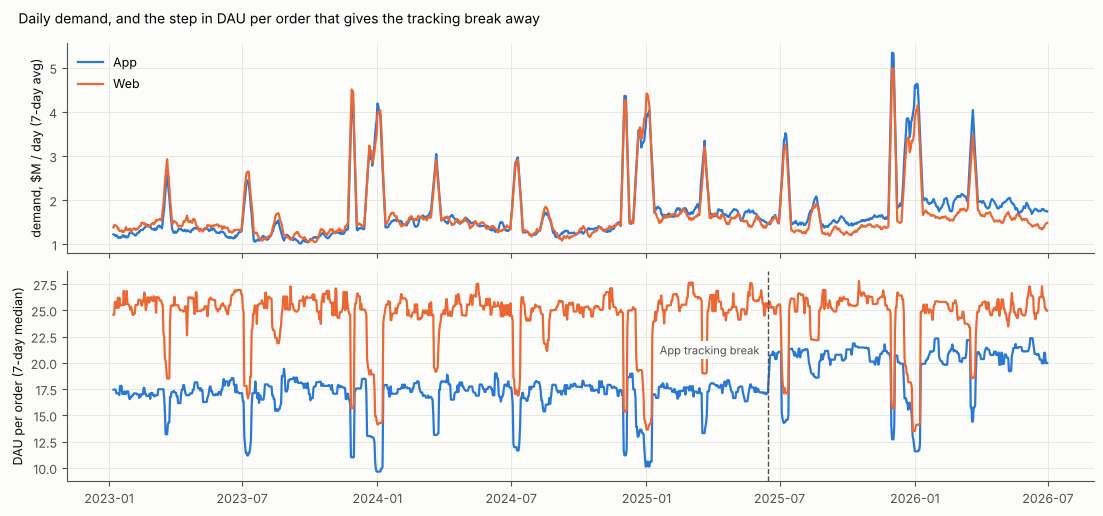

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
for ch, c in (("App", BLUE), ("Web", ORANGE)):
    g = daily[daily.channel == ch].set_index("date")
    axes[0].plot(g["demand"].rolling(7).mean() / 1e6, color=c, lw=1.6, label=ch)
    axes[1].plot((g["dau"] / g["orders"]).rolling(7).median(), color=c, lw=1.6, label=ch)
axes[0].set_ylabel("demand, $M / day (7-day avg)")
axes[1].set_ylabel("DAU per order (7-day median)")
axes[1].axvline(pd.Timestamp(truth.break_date), color=MUTED, ls="--", lw=1)
axes[1].annotate("App tracking break", (pd.Timestamp(truth.break_date), 21.2),
                 xytext=(-6, 0), textcoords="offset points", color=MUTED, fontsize=8, va="center", ha="right", bbox=dict(fc="#fcfcfb", ec="none", pad=1.5))
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Daily demand, and the step in DAU per order that gives the tracking break away", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.savefig("../docs/data.png", dpi=150); plt.show()

## 2. Fit the model and compare the spend effects with the truth
Elasticity = % change in DAU for 1% more spend. The 95% interval uses HAC standard errors (daily errors are autocorrelated).

In [3]:
model = DemandModel().fit(daily)
print("tracking breaks found:", {k: [str(d.date()) for d in v] for k, v in model.breaks().items()})
eff = model.spend_effects()
dau = eff[eff.piece == "dau"].copy()
dau["true"] = [truth.dau_elasticity[c][m] for c, m in zip(dau.channel, dau.media)]
se = dau["elasticity"] / dau["t"]
dau["95% interval"] = [f"{a:.3f} to {b:.3f}" for a, b in zip(dau.elasticity - 1.96 * se, dau.elasticity + 1.96 * se)]
dau[["channel", "media", "true", "elasticity", "95% interval", "t"]].round(3)

tracking breaks found: {'App': ['2025-06-15'], 'Web': []}


,channel,media,true,elasticity,95% interval,t
0,App,search,0.05,0.061,0.049 to 0.074,9.339
1,App,social,0.07,0.052,0.040 to 0.064,8.424
4,Web,search,0.08,0.081,0.067 to 0.094,11.812
5,Web,social,0.04,0.052,0.039 to 0.066,7.614


Estimates land within 0.02 of the truth, and three of the four 95% intervals contain it. App social is underestimated: search and social both ramp up in Q4, which the yearly seasonality also explains, so some of the credit is shared or misplaced. That is the honest limit of observational data, and why a lift test is the next step for any spend decision.

### Why the controls matter
Spend is higher during sale events. Drop the event terms and the model credits spend for the event lift:

In [4]:
naive = DemandModel(ModelConfig(use_events=False)).fit(daily).spend_effects()
cmp = dau[["channel", "media", "true", "elasticity"]].merge(
    naive[naive.piece == "dau"][["channel", "media", "elasticity"]].rename(columns={"elasticity": "without event controls"}),
    on=["channel", "media"])
cmp.round(3)

,channel,media,true,elasticity,without event controls
0,App,search,0.05,0.061,0.139
1,App,social,0.07,0.052,0.089
2,Web,search,0.08,0.081,0.158
3,Web,social,0.04,0.052,0.088


## 3. Rolling-origin backtest
One refit per month from Jul 2024, each trained only on earlier days and forecasting 90 days ahead. The forecast days get their actual promos and spend, so this scores the model given its inputs. The benchmark is *same weekday last year × recent year-on-year growth*.

In [5]:
bt = rolling_backtest(daily, pd.date_range("2024-07-01", "2026-03-01", freq="MS"), horizon=90)
summary = summarize_backtest(bt)
summary.pivot(index="channel", columns="forecast", values=["30-day WAPE", "bias"]).round(3)

30-day WAPE          bias       
forecast       model  naive  model  naive
channel                                  
App            0.020  0.079  0.008 -0.000
Total          0.013  0.081  0.005 -0.003
Web            0.018  0.087  0.001 -0.006

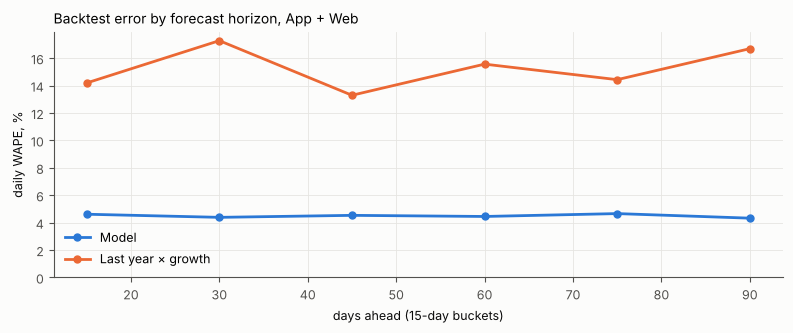

In [6]:
tot = bt.groupby(["origin", "date", "days_ahead"], as_index=False)[["demand", "model", "naive"]].sum()
tot["bucket"] = (tot.days_ahead - 1) // 15 * 15 + 15
by_h = tot.groupby("bucket").apply(lambda g: pd.Series({k: (g[k] - g.demand).abs().sum() / g.demand.sum() for k in ("model", "naive")}),
                                    include_groups=False)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(by_h.index, 100 * by_h["model"], color=BLUE, lw=2, marker="o", ms=5, label="Model")
ax.plot(by_h.index, 100 * by_h["naive"], color=ORANGE, lw=2, marker="o", ms=5, label="Last year × growth")
ax.set_xlabel("days ahead (15-day buckets)"); ax.set_ylabel("daily WAPE, %"); ax.set_ylim(0)
ax.legend(frameon=False)
ax.set_title("Backtest error by forecast horizon, App + Web", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig("../docs/backtest.png", dpi=150); plt.show()

## 4. Back-forecast: what the model would have said on 2026-01-01
Trained on 2025 and earlier only. Two versions of the inputs for 2026:
- **known on the day:** promos and spend copied from the same weekday last year (the event calendar is known ahead)
- **actual:** what really ran (shows how much of the miss is the model and how much is not knowing the plan)

In [7]:
known = back_forecast(daily, "2026-01-01", "2026-06-30", promo="last_year", spend="last_year")
actual = back_forecast(daily, "2026-01-01", "2026-06-30", promo="actual", spend="actual")
view = monthly_view(known)[["actual $M", "forecast $M", "miss %"]].join(
    monthly_view(actual)[["forecast $M", "miss %"]], rsuffix=" (actual inputs)")
view

,actual $M,forecast $M,miss %,forecast $M (actual inputs),miss % (actual inputs)
month,,,,,
2026-01,138.37,124.81,-9.80,132.89,-3.96
2026-02,99.30,104.14,4.88,100.40,1.10
2026-03,143.77,138.20,-3.88,142.21,-1.09
2026-04,104.45,107.91,3.32,107.10,2.54
2026-05,108.22,107.55,-0.62,108.39,0.16
2026-06,96.52,99.98,3.59,96.06,-0.47


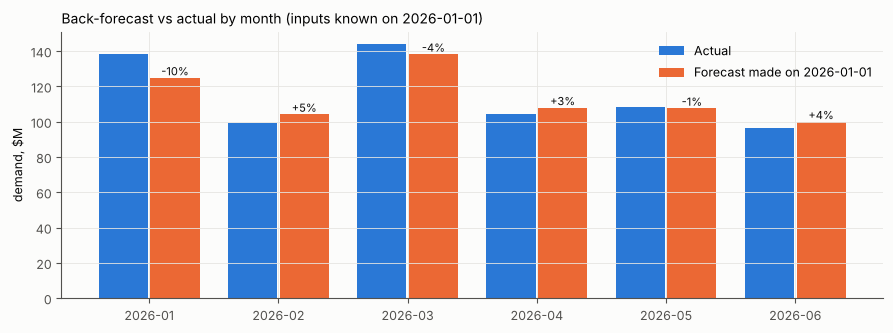

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(view))
ax.bar(x - 0.2, view["actual $M"], 0.38, color=BLUE, label="Actual")
ax.bar(x + 0.2, view["forecast $M"], 0.38, color=ORANGE, label="Forecast made on 2026-01-01")
for xi, m in zip(x, view["miss %"]):
    ax.text(xi + 0.2, view["forecast $M"].iloc[xi], f"{m:+.0f}%", ha="center", va="bottom", fontsize=8, color=INK)
ax.set_xticks(x); ax.set_xticklabels(view.index); ax.set_ylabel("demand, $M")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Back-forecast vs actual by month (inputs known on 2026-01-01)", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig("../docs/backforecast.png", dpi=150); plt.show()

## 5. What another 10% of spend buys
Model trained up to 2026-03-31, applied to Apr to Jun 2026 with each media's spend 10% higher.

In [9]:
m = DemandModel().fit(daily[daily.date < "2026-04-01"])
future = daily[daily.date >= "2026-04-01"][["date", "channel", "event", "promo_share", "discount_depth", "spend_search", "spend_social"]]
pd.DataFrame([spend_response(m, future, media) for media in ("search", "social")]).round(2)

,media,extra_spend,extra_demand,marginal_roas
0,search,591880.67,1986750.63,3.36
1,social,349548.83,759853.74,2.17


## Takeaways
- The model recovers the true spend elasticities to within about 0.02, and finds the tracking break from the data.
- Leaving out the event controls roughly doubles the estimated spend effect: spend and sale events move together.
- Every number above is produced without the model seeing the days it forecasts (see `tests/`).
- Synthetic data follows the model's own structure, so the accuracy here is optimistic. Real data adds effects the model doesn't have; the method for measuring that honestly is the same.